
EVALUATING: ec2_cpu_utilization_825cc2.csv
Training observations: 2412
Validation observations: 804
Test observations: 804
Test labeled anomalies: 0


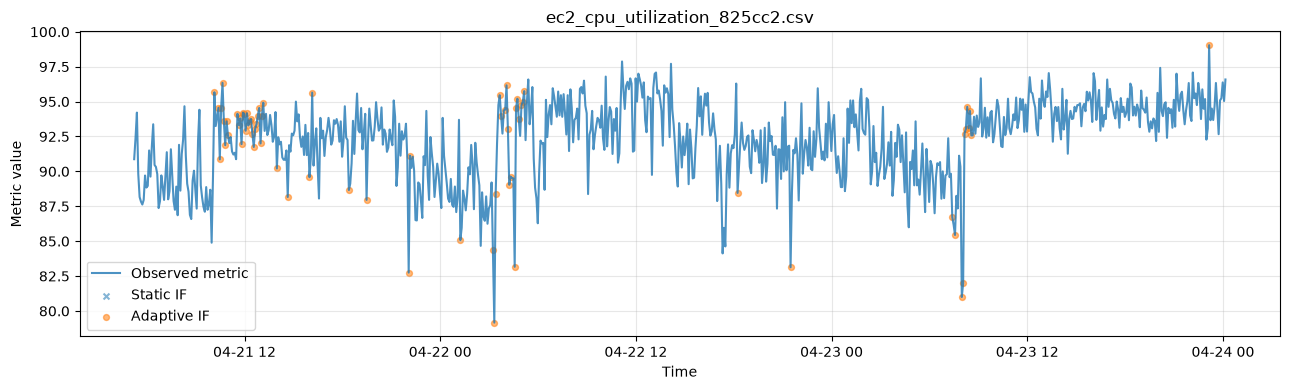


EVALUATING: ec2_network_in_257a54.csv
Training observations: 2412
Validation observations: 804
Test observations: 804
Test labeled anomalies: 0


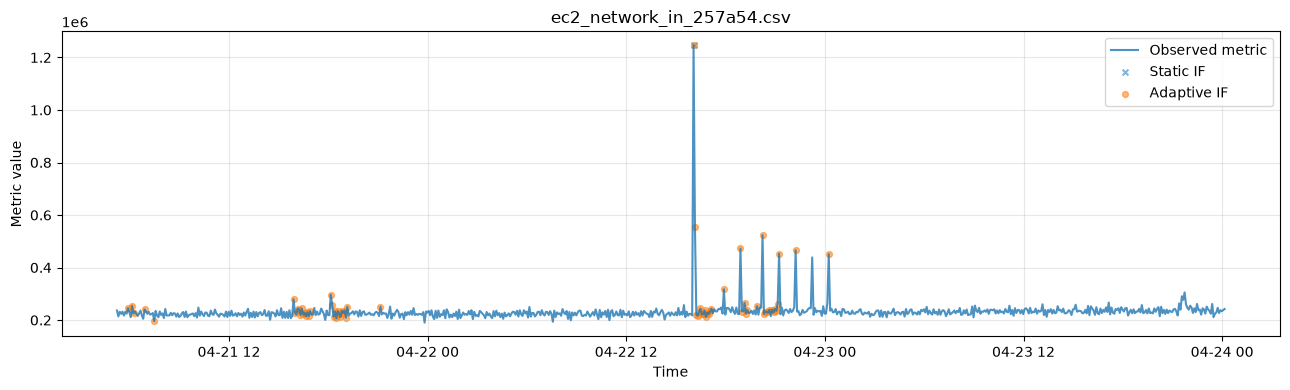


EVALUATING: elb_request_count_8c0756.csv
Training observations: 2412
Validation observations: 804
Test observations: 804
Test labeled anomalies: 201


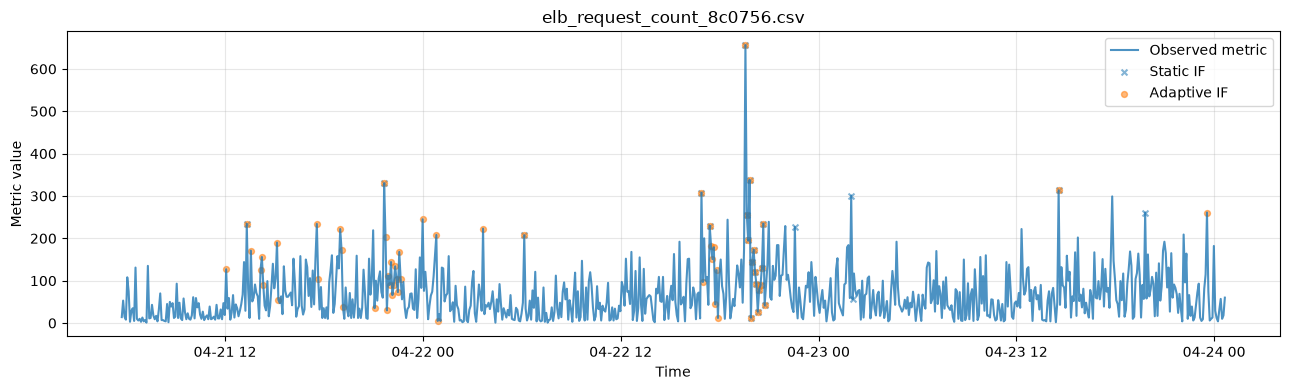


DAY 5 — PER-SERIES PERFORMANCE


,series,model,test_rows,test_anomalies,event_windows,detected_windows,partial_windows,event_recall,TP,FP,FN,TN,precision,recall,f1,false_positive_rate
0,ec2_cpu_utilization_825cc2.csv,Static IF,804,0,0,0,0,NaN,0,0,0,804,NaN,NaN,NaN,0.0000
1,ec2_cpu_utilization_825cc2.csv,Adaptive IF,804,0,0,0,0,NaN,0,68,0,736,0.0000,NaN,0.0000,0.0846
2,ec2_network_in_257a54.csv,Static IF,804,0,0,0,0,NaN,0,1,0,803,0.0000,NaN,0.0000,0.0012
3,ec2_network_in_257a54.csv,Adaptive IF,804,0,0,0,0,NaN,0,65,0,739,0.0000,NaN,0.0000,0.0808
4,elb_request_count_8c0756.csv,Static IF,804,201,1,1,0,1.0,20,5,181,598,0.8000,0.0995,0.1770,0.0083
5,elb_request_count_8c0756.csv,Adaptive IF,804,201,1,1,0,1.0,24,34,177,569,0.4138,0.1194,0.1853,0.0564



DAY 5 — AGGREGATE PERFORMANCE


,model,TP,FP,FN,TN,precision,recall,f1,false_positive_rate,event_windows,detected_windows
0,Adaptive IF,24,167,177,2044,0.1257,0.1194,0.1224,0.0755,1,1
1,Static IF,20,6,181,2205,0.7692,0.0995,0.1762,0.0027,1,1



Saved results to: C:\Users\rvmkr\saas-aiops-observability\data\processed\day5
DAY 5 EXPERIMENT COMPLETE


In [ ]:

# ==========================================================
# UC BERKELEY AI/ML CAPSTONE — DAY 5
# Static vs Adaptive Isolation Forest
# Fresh NAB AWS CloudWatch evaluation datasets
# ==========================================================

from pathlib import Path
from urllib.request import urlretrieve
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import confusion_matrix

SEED = 42
BASE = "https://raw.githubusercontent.com/numenta/NAB/master"

ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent

assert (ROOT / "requirements.txt").exists(), (
    "Open the notebook from the project root or notebooks directory."
)
RAW = ROOT / "data/raw/nab"
OUT = ROOT / "data/processed/day5"

RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# New datasets not used during Day 3/4 model inspection
DATASETS = [
    "ec2_cpu_utilization_825cc2.csv",
    "ec2_network_in_257a54.csv",
    "elb_request_count_8c0756.csv"
]

LABEL_PATH = RAW / "anomaly_windows.json"

if not LABEL_PATH.exists():
    urlretrieve(
        BASE + "/labels/combined_windows.json",
        LABEL_PATH
    )

with open(LABEL_PATH, encoding="utf-8") as f:
    annotations = json.load(f)

# Fixed experimental configuration
TRAIN_FRACTION = 0.60
VALIDATION_FRACTION = 0.20
ROLLING_HISTORY = 288
RETRAIN_EVERY = 48
THRESHOLD_QUANTILE = 0.98
N_ESTIMATORS = 100

FEATURES = [
    "value",
    "past_mean",
    "past_std",
    "change"
]

def prepare_data(filename):
    source = "realAWSCloudwatch/" + filename
    path = RAW / filename

    if not path.exists():
        urlretrieve(
            BASE + "/data/" + source,
            path
        )

    df = pd.read_csv(path)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["value"] = pd.to_numeric(
        df["value"], errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp", "value"])
          .drop_duplicates(subset=["timestamp"])
          .sort_values("timestamp")
          .reset_index(drop=True)
    )

    # Use only past observations for reference features
    previous = df["value"].shift(1)
    history = previous.rolling(12, min_periods=12)

    df["past_mean"] = history.mean()
    df["past_std"] = history.std()
    df["change"] = df["value"] - previous

    df = df.replace(
        [np.inf, -np.inf], np.nan
    ).dropna(subset=FEATURES).reset_index(drop=True)

    if source not in annotations:
        raise KeyError("Missing labels: " + source)

    windows = [
        (pd.Timestamp(start), pd.Timestamp(end))
        for start, end in annotations[source]
    ]

    df["label"] = 0
    for start, end in windows:
        df.loc[
            df["timestamp"].between(start, end),
            "label"
        ] = 1

    return df, windows


def fit_detector(reference):
    scaler = RobustScaler()
    X = scaler.fit_transform(reference[FEATURES])

    model = IsolationForest(
        n_estimators=N_ESTIMATORS,
        contamination="auto",
        random_state=SEED,
        n_jobs=-1
    )
    model.fit(X)

    scores = -model.score_samples(X)
    threshold = np.quantile(
        scores, THRESHOLD_QUANTILE
    )

    return scaler, model, threshold


def predict_detector(frame, fitted):
    scaler, model, threshold = fitted
    X = scaler.transform(frame[FEATURES])
    scores = -model.score_samples(X)

    return (scores > threshold).astype(int), scores


def evaluate(y, p):
    tn, fp, fn, tp = confusion_matrix(
        y, p, labels=[0, 1]
    ).ravel()

    precision = (
        tp / (tp + fp) if tp + fp else np.nan
    )
    recall = (
        tp / (tp + fn) if tp + fn else np.nan
    )
    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if fp + tn else np.nan
    )

    return dict(
        TP=tp, FP=fp, FN=fn, TN=tn,
        precision=precision,
        recall=recall,
        f1=f1,
        false_positive_rate=fpr
    )


def window_detection_rate(test, windows, pred_col):
    # Count annotation windows overlapping the test period.
    # Partially observed windows are included and flagged.
    start_test = test["timestamp"].min()
    end_test = test["timestamp"].max()

    total = 0
    detected = 0
    partial = 0

    for start, end in windows:
        if end < start_test or start > end_test:
            continue

        total += 1

        if start < start_test or end > end_test:
            partial += 1

        relevant = test[
            test["timestamp"].between(start, end)
        ]

        if relevant[pred_col].eq(1).any():
            detected += 1

    rate = detected / total if total else np.nan
    return total, detected, partial, rate


all_results = []
all_predictions = []

for filename in DATASETS:
    print("\n" + "=" * 60)
    print("EVALUATING:", filename)
    print("=" * 60)

    df, windows = prepare_data(filename)
    n = len(df)

    train_end = int(n * TRAIN_FRACTION)
    test_start = int(
        n * (TRAIN_FRACTION + VALIDATION_FRACTION)
    )

    train = df.iloc[:train_end].copy()
    validation = df.iloc[train_end:test_start].copy()
    test = df.iloc[test_start:].copy()

    if len(train) < ROLLING_HISTORY or len(test) == 0:
        raise ValueError("Insufficient observations: " + filename)

    # Model A: static detector, trained once
    static_fitted = fit_detector(train)
    static_pred, static_scores = predict_detector(
        test, static_fitted
    )

    # Model B: adaptive detector
    # At each block, only use data strictly before
    # that block. No test labels are used.
    adaptive_pred = np.zeros(len(test), dtype=int)
    adaptive_scores = np.full(len(test), np.nan)

    for offset in range(0, len(test), RETRAIN_EVERY):
        absolute_start = test_start + offset
        absolute_end = min(
            absolute_start + RETRAIN_EVERY, n
        )

        history_start = max(
            0, absolute_start - ROLLING_HISTORY
        )

        reference = df.iloc[
            history_start:absolute_start
        ]

        upcoming = df.iloc[
            absolute_start:absolute_end
        ]

        fitted = fit_detector(reference)
        predictions, scores = predict_detector(
            upcoming, fitted
        )

        count = len(upcoming)
        adaptive_pred[offset:offset + count] = predictions
        adaptive_scores[offset:offset + count] = scores

    test["static_pred"] = static_pred
    test["adaptive_pred"] = adaptive_pred
    test["static_score"] = static_scores
    test["adaptive_score"] = adaptive_scores
    test["series"] = filename

    y = test["label"].to_numpy()

    for method, column in [
        ("Static IF", "static_pred"),
        ("Adaptive IF", "adaptive_pred")
    ]:
        metrics = evaluate(
            y, test[column].to_numpy()
        )

        events, found, partial, event_recall = (
            window_detection_rate(test, windows, column)
        )

        all_results.append({
            "series": filename,
            "model": method,
            "test_rows": len(test),
            "test_anomalies": int(y.sum()),
            "event_windows": events,
            "detected_windows": found,
            "partial_windows": partial,
            "event_recall": event_recall,
            **metrics
        })

    all_predictions.append(test)

    print("Training observations:", len(train))
    print("Validation observations:", len(validation))
    print("Test observations:", len(test))
    print("Test labeled anomalies:", int(y.sum()))

    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(
        test["timestamp"], test["value"],
        label="Observed metric", alpha=0.8
    )

    for col, marker, label in [
        ("static_pred", "x", "Static IF"),
        ("adaptive_pred", "o", "Adaptive IF")
    ]:
        subset = test[test[col] == 1]
        ax.scatter(
            subset["timestamp"],
            subset["value"],
            marker=marker,
            s=18,
            alpha=0.55,
            label=label
        )

    ax.set_title(filename)
    ax.set_xlabel("Time")
    ax.set_ylabel("Metric value")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------
# Results and aggregate evaluation
# ----------------------------------------------------------

results = pd.DataFrame(all_results)
predictions = pd.concat(
    all_predictions, ignore_index=True
)

print("\nDAY 5 — PER-SERIES PERFORMANCE")
display(results.round(4))

summary = []

for model_name, group in results.groupby("model"):
    tp = int(group["TP"].sum())
    fp = int(group["FP"].sum())
    fn = int(group["FN"].sum())
    tn = int(group["TN"].sum())

    summary.append({
        "model": model_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": tp/(tp+fp) if tp+fp else np.nan,
        "recall": tp/(tp+fn) if tp+fn else np.nan,
        "f1": (
            2*tp/(2*tp+fp+fn)
            if 2*tp+fp+fn else np.nan
        ),
        "false_positive_rate": (
            fp/(fp+tn) if fp+tn else np.nan
        ),
        "event_windows": int(group["event_windows"].sum()),
        "detected_windows": int(
            group["detected_windows"].sum()
        )
    })

summary = pd.DataFrame(summary)

print("\nDAY 5 — AGGREGATE PERFORMANCE")
display(summary.round(4))

results.to_csv(
    OUT / "per_series_comparison.csv", index=False
)
summary.to_csv(
    OUT / "model_comparison.csv", index=False
)
predictions.to_csv(
    OUT / "test_predictions.csv", index=False
)

print("\nSaved results to:", OUT)
print("DAY 5 EXPERIMENT COMPLETE")
